# Exercise 1: Business cycle correlations

For this exercise, you'll be using macroeconomic data from the folder `data/FRED`.

1.  There are seven decade-specific files named `FRED_monthly_YYYY.csv` where `YYYY` identifies the decade by its first year (`YYYY` takes on the values 1950, 1960, ..., 2010). Write a loop that reads in all seven files as DataFrames and stores them in a list.

    *Hint:* Recall from the lecture that you should use `pd.read_csv(..., parse_dates=['DATE'])` to automatically parse strings stored in the `DATE` column as dates.
2.  Use 
    [`pd.concat()`](https://pandas.pydata.org/docs/reference/api/pandas.concat.html)
    to concatenate these data sets into a single `DataFrame` and set the `DATE` column as the index.
3.  You realize that your data does not include GDP since this variable is only reported at quarterly frequency.
    Load the GDP data from the file `GDP.csv` and merge it with your monthly data using an _inner join_.

    Explain what happens to the number of observations when you merge the monthly and quarterly datasets.

4.  You want to compute how (percent) changes in the variables in your data
    correlate with percent changes in GDP.

    1. Create a _new_ `DataFrame` which contains the percent changes in CPI and GDP (using 
    [`pct_change()`](https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.pct_change.html)),
    and the percentage-point changes for the remaining variables (using 
    [`diff()`](https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.diff.html)).
    2.  Compute the correlation of the percent changes in GDP with the (percent)
        changes in all other variables using 
    [`corr()`](https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.corr.html).
    What do the sign and magnitude of the correlation coefficient tell you?

In [145]:
import pandas as pd
import numpy as np
DATA_PATH = '../../data' 

data = []

for year in range(1950, 2020, 10):

 file = f'{DATA_PATH}/FRED/FRED_monthly_{year}.csv'
 print(f'Reading in from {file}')

 df = pd.read_csv(file, parse_dates = ['DATE'])
 data.append(df)

df = pd.concat(data, ignore_index = True)

df





Reading in from ../../data/FRED/FRED_monthly_1950.csv
Reading in from ../../data/FRED/FRED_monthly_1960.csv
Reading in from ../../data/FRED/FRED_monthly_1970.csv
Reading in from ../../data/FRED/FRED_monthly_1980.csv
Reading in from ../../data/FRED/FRED_monthly_1990.csv
Reading in from ../../data/FRED/FRED_monthly_2000.csv
Reading in from ../../data/FRED/FRED_monthly_2010.csv


,DATE,CPI,UNRATE,FEDFUNDS,REALRATE,LFPART
0,1950-01-01,23.5,6.5,NaN,NaN,58.9
1,1950-02-01,23.6,6.4,NaN,NaN,58.9
2,1950-03-01,23.6,6.3,NaN,NaN,58.8
3,1950-04-01,23.6,5.8,NaN,NaN,59.2
4,1950-05-01,23.8,5.5,NaN,NaN,59.1
...,...,...,...,...,...,...
835,2019-08-01,256.0,3.6,2.1,0.6,63.1
836,2019-09-01,256.4,3.5,2.0,0.3,63.2
837,2019-10-01,257.2,3.6,1.8,-0.0,63.3
838,2019-11-01,257.9,3.6,1.6,-0.2,63.3


In [146]:
import pandas as pd
import numpy as np
DATA_PATH = '../../data' 

gdp = f'{DATA_PATH}/FRED/GDP.csv'
df_gdp = pd.read_csv(gdp, parse_dates = ['DATE'])
df = pd.merge(df, df_gdp)

df_gdp


,DATE,GDP
0,1947-01-01,2182.7
1,1947-04-01,2176.9
2,1947-07-01,2172.4
3,1947-10-01,2206.5
4,1948-01-01,2239.7
...,...,...
313,2025-04-01,23771.0
314,2025-07-01,24026.8
315,2025-10-01,24055.7
316,2026-01-01,24180.4


In [147]:
df

,DATE,CPI,UNRATE,FEDFUNDS,REALRATE,LFPART,GDP
0,1950-01-01,23.5,6.5,NaN,NaN,58.9,2346.1
1,1950-04-01,23.6,5.8,NaN,NaN,59.2,2417.7
2,1950-07-01,24.1,5.0,NaN,NaN,59.1,2511.1
3,1950-10-01,24.5,4.2,NaN,NaN,59.4,2559.2
4,1951-01-01,25.4,3.7,NaN,NaN,59.1,2594.0
...,...,...,...,...,...,...,...
275,2018-10-01,252.8,3.8,2.2,-0.2,62.9,20304.9
276,2019-01-01,252.6,4.0,2.4,0.6,63.1,20431.6
277,2019-04-01,255.2,3.7,2.4,3.1,62.8,20602.3
278,2019-07-01,255.8,3.7,2.4,1.1,63.1,20843.3


In [148]:
df_changes = df[['GDP']].pct_change() * 100

df_changes['UNRATE'] = df['UNRATE'].diff()

df_changes.corr()


,GDP,UNRATE
GDP,1.000000,-0.564872
UNRATE,-0.564872,1.000000


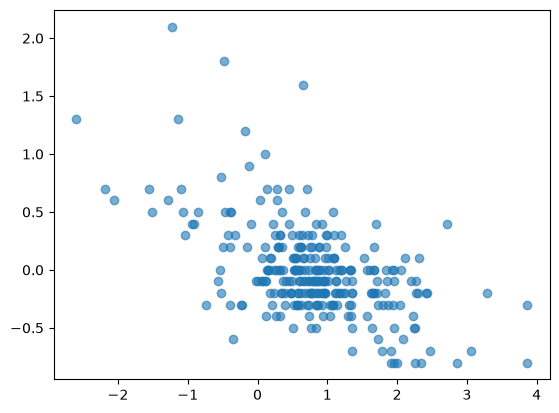

In [149]:
import matplotlib.pyplot as plt

plt.scatter(df_changes['GDP'], df_changes['UNRATE'], alpha=0.6)


***
# Exercise 2: Loading many data files

Python can find files matching a pattern using
[`glob.glob()`](https://docs.python.org/3/library/glob.html).

Load the seven decade files `FRED_monthly_YYYY.csv` in the local `data/FRED`
folder using `glob.glob()`. Match names starting with `FRED_monthly_1` or
`FRED_monthly_2`, and store the DataFrames in a list. Parse `DATE` as dates and
set it as the index. Concatenate the list along the row axis and sort by date.

***
# Exercise 3: Weekly returns of the Magnificent Seven

In this exercise, you are asked to analyze the weekly stock market returns of the
so-called Magnificent Seven, which are some of the most successful tech companies
of the last few decades:
Apple (AAPL), Amazon (AMZN), Alphabet/Google (GOOGL), Meta (META), Microsoft (MSFT), Nvidia (NVDA), and Tesla (TSLA).

The data for this exercise is located in the folder `data/stockmarket/`.

1.  For each of the seven stocks listed above, there is a corresponding CSV file in this directory (based on the ticker symbol).

    1.  For each ticker symbol, load the corresponding CSV file and make sure that
        the `Date` column is set as the index.

        The DataFrame has two columns, `Open` and `Close`, which contain the
        opening and closing prices for each trading day.

    2.  Use 
        [`resample()`](https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.resample.html)
        to resample the daily data to a weekly frequency by specifying `resample('W')`, and compute the weekly returns in percent:

        $$
        \text{Weekly returns} = \frac{\text{Close price on last day} - \text{Open price on first day}}{\text{Open price on first day}} \times 100
        $$

        *Hint:* You can obtain the first and last observations using the 
        [`first()`](https://pandas.pydata.org/docs/reference/api/pandas.api.typing.Resampler.first.html) and 
        [`last()`](https://pandas.pydata.org/docs/reference/api/pandas.api.typing.Resampler.last.html)
        methods.

    3.  Append these returns to a list so you can merge them into a single DataFrame later.

2.  Merge the weekly returns into a single DataFrame, keeping the intersection of
    dates available for all 7 stocks. Discard the first and last common weeks,
    which are incomplete in these files.

    *Hint:* This can be achieved using either 
    [`pd.concat()`](https://pandas.pydata.org/docs/reference/api/pandas.concat.html), 
    [`pd.merge()`](https://pandas.pydata.org/docs/reference/api/pandas.merge.html), or 
    [`DataFrame.join()`](https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.join.html).

3.  Finally, you are interested in how the weekly returns are correlated across the 7 stocks. 

    1.  Compute and report the pairwise correlations using 
        [`DataFrame.corr()`](https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.corr.html).

    2.  Create a figure with a 7-by-7 grid of subplots showing the pairwise scatter
        plots of weekly returns for each combination of stocks.

        You can do this either with the 
        [`scatter_matrix()`](https://pandas.pydata.org/docs/reference/api/pandas.plotting.scatter_matrix.html)
        function contained in `pandas.plotting`, or manually build the figure using Matplotlib functions.

    3.  **[Advanced]** Add the corresponding correlation coefficient to each
        off-diagonal subplot (e.g., about 0.43 for AAPL and AMZN).

***
# Exercise 4: Decade averages of macro time series


For this exercise, you'll be using macroeconomic data from the folder `data/FRED`.

1.  There are five files containing monthly observations on annual inflation (INFLATION), the Fed Funds rate (FEDFUNDS), the labor force participation rate (LFPART), the 1-year real interest rate (REALRATE), and the unemployment rate (UNRATE).

    1.  Write a loop to import these files and store the individual DataFrames in a list.

        *Hint:* Recall from the lecture that you should use 
        `pd.read_csv(..., parse_dates=['DATE'], index_col='DATE')` to automatically parse strings stored in the `DATE` column as dates and set the `DATE`
        column as the index.

    2.  Use 
        [`pd.concat()`](https://pandas.pydata.org/docs/reference/api/pandas.concat.html)
        to concatenate this list of DataFrames along the column dimension
        using an outer join (`join='outer'`) to obtain a merged data set.

2.  You want to compute the average value of each variable by decade, but you want to include only decades without _any_ missing values for _all_ variables.

    1.  Create a variable `Decade` which stores the decade (1940, 1950, ...) for each observation.

        *Hint:* You should have set `DATE` as the `DataFrame` index. Then you can access the calendar year using the attribute `df.index.year`, which can be used to compute the decade.

    2.  Create an indicator variable which takes on the value `True`
        whenever all five variables have nonmissing values on a given date, and
        `False` if at least one variable has a missing observation.

    3.  Aggregate this indicator to decades using 
        [`groupby()`](https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.groupby.html)
        so that the indicator takes on the value `True` whenever
        _all_ variables in a given decade have no missing values, and `False`
        otherwise.

        *Hint:* You can use the 
        [`all()`](https://pandas.pydata.org/docs/reference/api/pandas.api.typing.SeriesGroupBy.all.html)
        aggregation for this.

    4.  Merge this decade-level indicator data back into the original `DataFrame` (_many-to-one_ merge). 
3.  Using this indicator, drop all observations which are in a decade with missing values.
4.  Compute the decade average for each variable.

**Challenge**

-   Your pandas guru friend claims that all the steps in 2.2 to 2.4 can be done
    with a single expression using 
    [`transform()`](https://pandas.pydata.org/docs/reference/api/pandas.api.typing.SeriesGroupBy.transform.html).
    Can you come up with a solution?

In [150]:
import pandas as pd
import numpy as np
DATA_PATH = '../../data' 

for year in range(2013, 2026):
 file = f'{DATA_PATH}/SCE_10pct/SCE_{year}.csv'
 print(f'Reading in file{file}')

 df = pd.read_csv(file, parse_dates=['date'])

data.append(df_SCE)

df_SCE = pd.concat(data, ignore_index = True)

Reading in file../../data/SCE_10pct/SCE_2013.csv
Reading in file../../data/SCE_10pct/SCE_2014.csv
Reading in file../../data/SCE_10pct/SCE_2015.csv
Reading in file../../data/SCE_10pct/SCE_2016.csv
Reading in file../../data/SCE_10pct/SCE_2017.csv
Reading in file../../data/SCE_10pct/SCE_2018.csv
Reading in file../../data/SCE_10pct/SCE_2019.csv
Reading in file../../data/SCE_10pct/SCE_2020.csv
Reading in file../../data/SCE_10pct/SCE_2021.csv
Reading in file../../data/SCE_10pct/SCE_2022.csv
Reading in file../../data/SCE_10pct/SCE_2023.csv
Reading in file../../data/SCE_10pct/SCE_2024.csv
Reading in file../../data/SCE_10pct/SCE_2025.csv


In [156]:
df_expect = df.groupby(['date', 'female'])[['infl_1y']].mean

df_expect = df.rename(columns={'infl_1y': 'expected'})

df_expect = df_expect.reset_index()

df_expect


,index,userid,date,female,expected
0,0,75016800,2025-01-01,0,-5.0
1,1,75017006,2025-01-01,0,4.0
2,2,75017163,2025-01-01,0,4.0
3,3,75018002,2025-01-01,0,-1.0
4,4,75018125,2025-01-01,0,5.0
...,...,...,...,...,...
941,941,75029946,2025-09-01,1,-10.0
942,942,75030026,2025-09-01,1,4.0
943,943,75030228,2025-09-01,1,8.0
944,944,75030275,2025-09-01,1,-25.0


In [ ]:
import pandas as pd
import numpy as np

DATA_PATH = '../../data' 

file = f'{DATA_PATH}/FRED/CPI.csv'
df_cpi = pd.read_csv(file, parse_dates=['DATE'])


: 